In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

images_dir = Path(
    "/content/drive/MyDrive/NIH_ChestXray14_Project/images"
)

image_files = list(images_dir.rglob("*.png"))

print("Total PNG images found:", len(image_files))
print("First 5 images:")

for image in image_files[:5]:
    print(image)

Total PNG images found: 5724
First 5 images:
/content/drive/MyDrive/NIH_ChestXray14_Project/images/subset_images/00017846_006.png
/content/drive/MyDrive/NIH_ChestXray14_Project/images/subset_images/00016596_001.png
/content/drive/MyDrive/NIH_ChestXray14_Project/images/subset_images/00017835_032.png
/content/drive/MyDrive/NIH_ChestXray14_Project/images/subset_images/00016291_054.png
/content/drive/MyDrive/NIH_ChestXray14_Project/images/subset_images/00016258_002.png


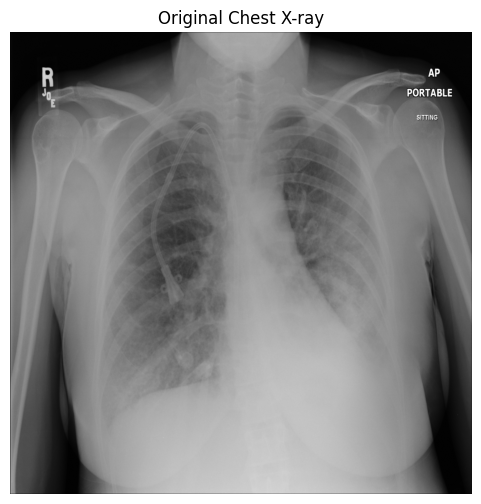

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Select one image
image_path = image_files[0]

# Open image
image = Image.open(image_path).convert("L")

# Display image
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Original Chest X-ray")
plt.axis("off")
plt.show()

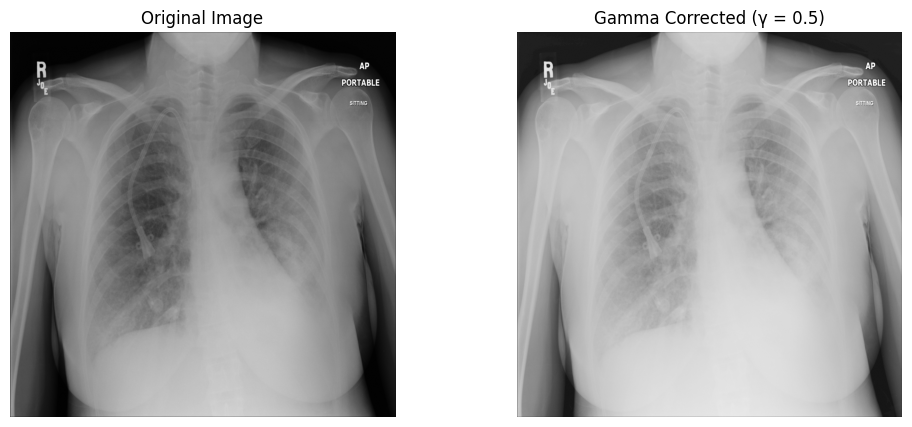

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

# Convert image to NumPy array
image_array = np.array(image).astype(np.float32) / 255.0

# Gamma value for experimentation
gamma = 0.5

# Apply gamma correction
gamma_image = np.power(image_array, gamma)

# Display original and gamma-corrected images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_array, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gamma_image, cmap="gray")
plt.title(f"Gamma Corrected (γ = {gamma})")
plt.axis("off")

plt.show()

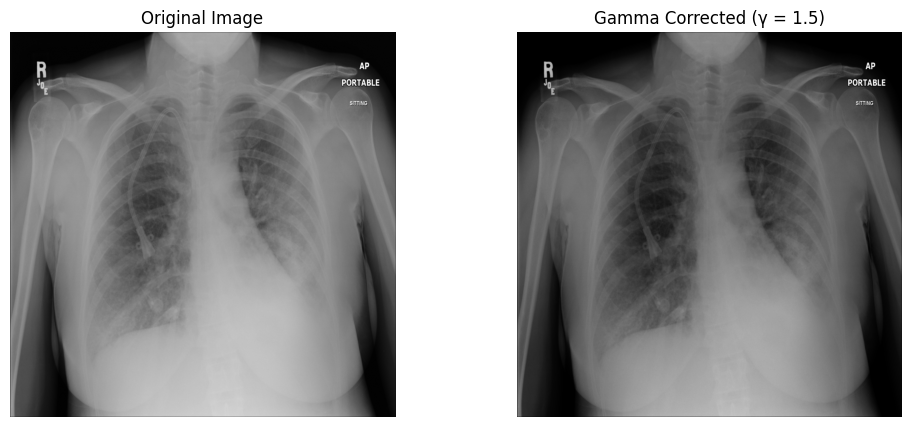

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

# Convert image to NumPy array
image_array = np.array(image).astype(np.float32) / 255.0

# Gamma value for experimentation
gamma = 1.5

# Apply gamma correction
gamma_image = np.power(image_array, gamma)

# Display original and gamma-corrected images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_array, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gamma_image, cmap="gray")
plt.title(f"Gamma Corrected (γ = {gamma})")
plt.axis("off")

plt.show()

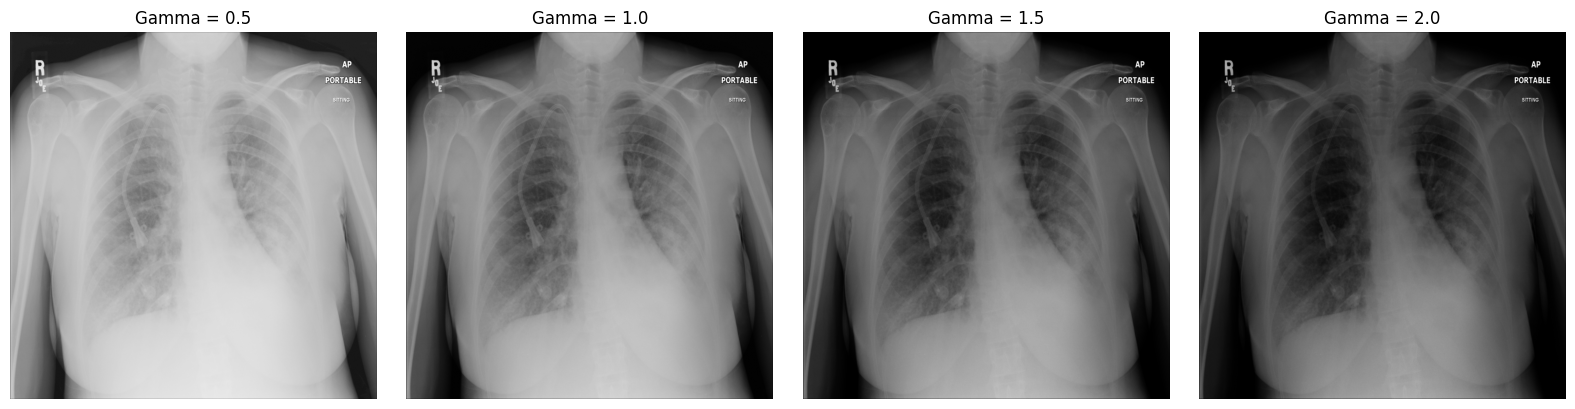

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

image_array = np.array(image).astype(np.float32) / 255.0

gamma_values = [0.5, 1.0, 1.5, 2.0]

plt.figure(figsize=(16, 4))

for i, gamma in enumerate(gamma_values):
    gamma_image = np.power(image_array, gamma)

    plt.subplot(1, 4, i + 1)
    plt.imshow(gamma_image, cmap="gray")
    plt.title(f"Gamma = {gamma}")
    plt.axis("off")

plt.tight_layout()
plt.show()

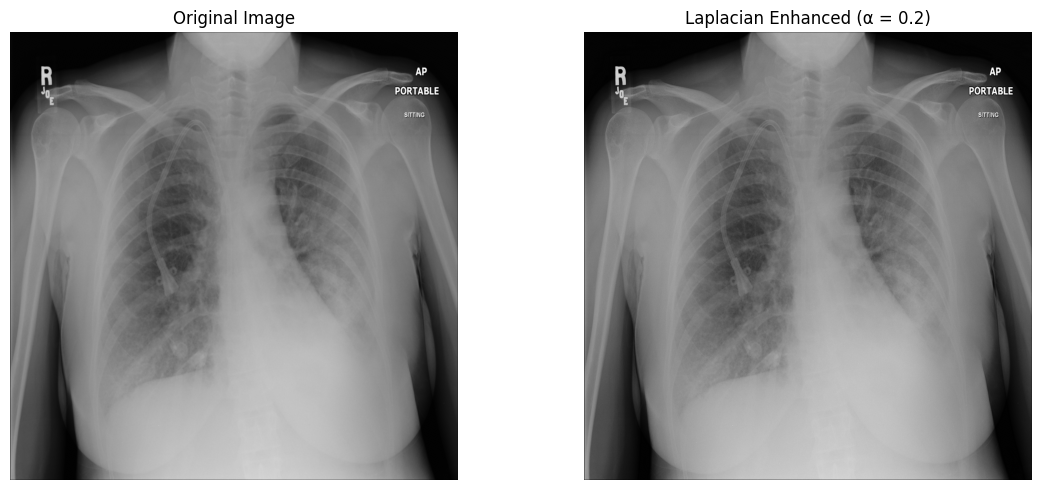

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Convert image to NumPy array
gray = np.array(image).astype(np.float32)

# Apply Laplacian filter
laplacian = cv2.Laplacian(gray, cv2.CV_32F)

# Laplacian sharpening
alpha = 0.2

enhanced_image = np.clip(
    gray - alpha * laplacian,
    0,
    255
).astype(np.uint8)

# Display original and Laplacian-enhanced image
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_image, cmap="gray")
plt.title(f"Laplacian Enhanced (α = {alpha})")
plt.axis("off")

plt.tight_layout()
plt.show()

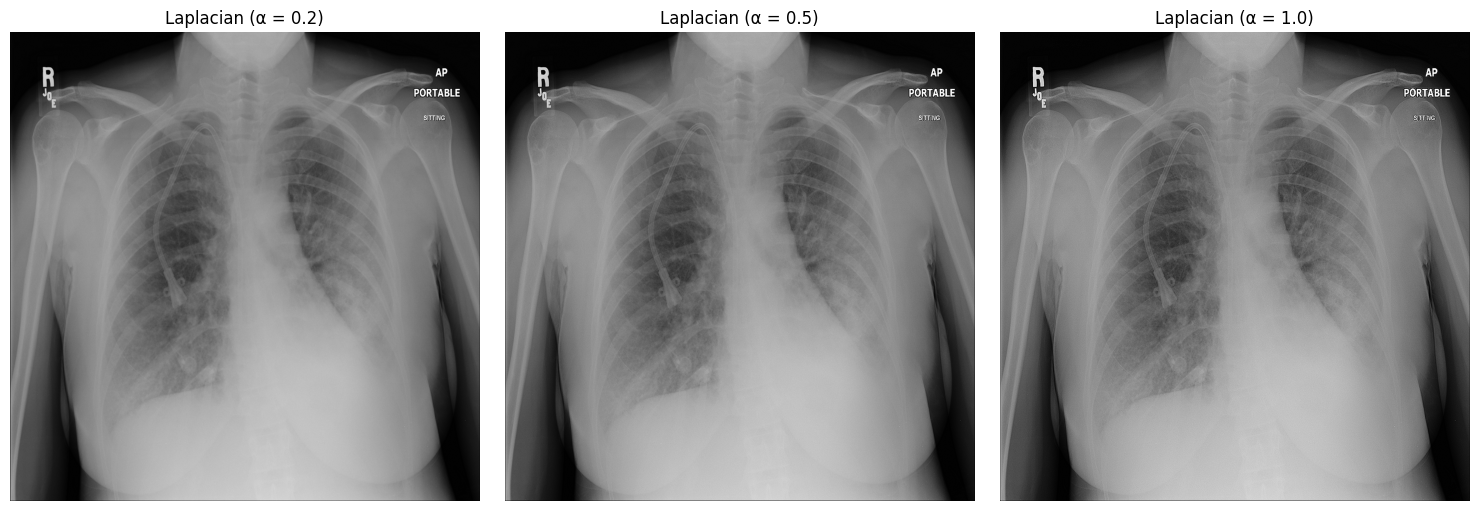

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

gray = np.array(image).astype(np.float32)

# Calculate Laplacian
laplacian = cv2.Laplacian(gray, cv2.CV_32F)

alpha_values = [0.2, 0.5, 1.0]

plt.figure(figsize=(15, 5))

for i, alpha in enumerate(alpha_values):
    enhanced_image = np.clip(
        gray - alpha * laplacian,
        0,
        255
    ).astype(np.uint8)

    plt.subplot(1, 3, i + 1)
    plt.imshow(enhanced_image, cmap="gray")
    plt.title(f"Laplacian (α = {alpha})")
    plt.axis("off")

plt.tight_layout()
plt.show()

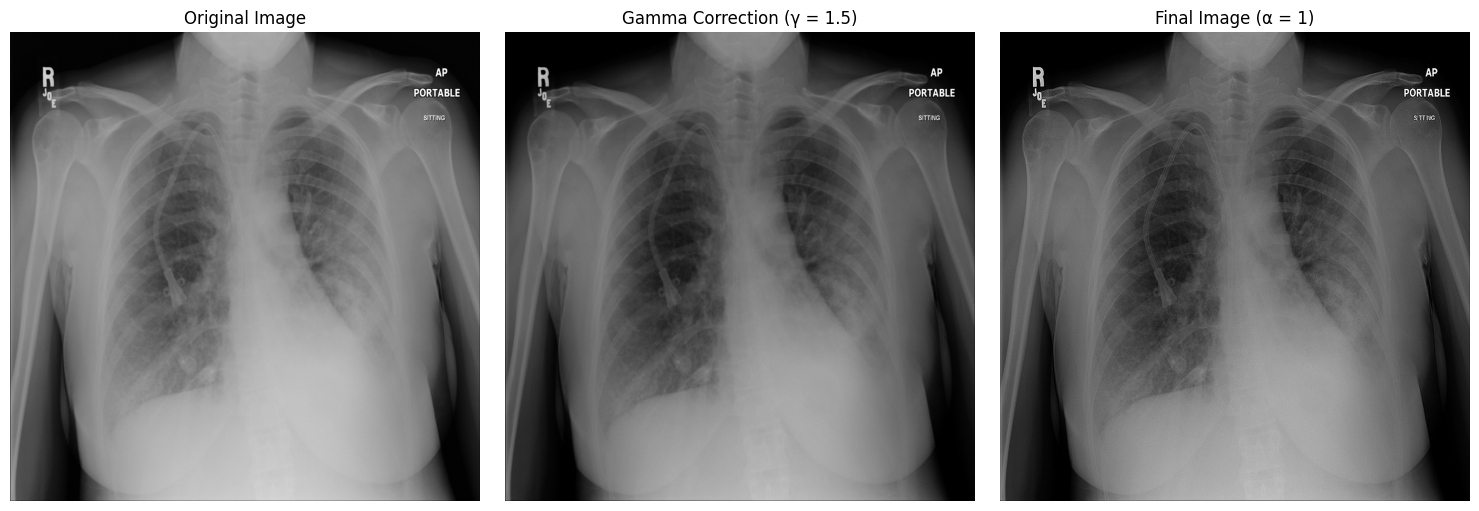

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Convert original image to normalized array
image_array = np.array(image).astype(np.float32) / 255.0

# Step 1: Gamma correction
gamma = 1.5
gamma_image = np.power(image_array, gamma)

# Convert to 0–255 format
gamma_uint8 = (gamma_image * 255).astype(np.uint8)

# Step 2: Laplacian sharpening
gray = gamma_uint8.astype(np.float32)

laplacian = cv2.Laplacian(gray, cv2.CV_32F)

alpha = 1

enhanced_image = np.clip(
    gray - alpha * laplacian,
    0,
    255
).astype(np.uint8)

# Display all stages
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_array, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gamma_image, cmap="gray")
plt.title(f"Gamma Correction (γ = {gamma})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(enhanced_image, cmap="gray")
plt.title(f"Final Image (α = {alpha})")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

# Project directories
project_dir = Path("/content/drive/MyDrive/NIH_ChestXray14_Project")

input_dir = project_dir / "images" / "subset_images"
output_dir = project_dir / "images" / "preprocessed_images"

# Create output folder
output_dir.mkdir(parents=True, exist_ok=True)

print("Input folder:", input_dir)
print("Output folder:", output_dir)
print("Output folder created successfully!")

Input folder: /content/drive/MyDrive/NIH_ChestXray14_Project/images/subset_images
Output folder: /content/drive/MyDrive/NIH_ChestXray14_Project/images/preprocessed_images
Output folder created successfully!


In [ ]:
import cv2
import numpy as np
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

# Input and output folders
input_dir = project_dir / "images" / "subset_images"
output_dir = project_dir / "images" / "preprocessed_images"

# Parameters
gamma = 1.5
alpha = 1.0

# Get all image files
image_files = sorted(input_dir.glob("*.png"))

print("Total images:", len(image_files))
print("Gamma value:", gamma)
print("Laplacian alpha:", alpha)

# Process images
processed_count = 0
failed_count = 0

for image_path in tqdm(image_files, desc="Processing images"):

    try:
        # Read image in grayscale
        gray = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if gray is None:
            failed_count += 1
            continue

        # Step 1: Gamma correction
        normalized = gray.astype(np.float32) / 255.0

        gamma_image = np.power(normalized, gamma)

        gamma_uint8 = np.clip(
            gamma_image * 255,
            0,
            255
        ).astype(np.uint8)

        # Step 2: Laplacian sharpening
        gray_float = gamma_uint8.astype(np.float32)

        laplacian = cv2.Laplacian(
            gray_float,
            cv2.CV_32F
        )

        enhanced_image = np.clip(
            gray_float - alpha * laplacian,
            0,
            255
        ).astype(np.uint8)

        # Save preprocessed image with the same filename
        output_path = output_dir / image_path.name

        cv2.imwrite(
            str(output_path),
            enhanced_image
        )

        processed_count += 1

    except Exception as e:
        failed_count += 1
        print(f"Error processing {image_path.name}: {e}")

print("\nProcessing completed!")
print("Successfully processed:", processed_count)
print("Failed images:", failed_count)
print("Output folder:", output_dir)

Total images: 2862
Gamma value: 1.5
Laplacian alpha: 1.0


Processing images:   0%|          | 0/2862 [00:00<?, ?it/s]


Processing completed!
Successfully processed: 2862
Failed images: 0
Output folder: /content/drive/MyDrive/NIH_ChestXray14_Project/images/preprocessed_images


Total preprocessed images: 2862


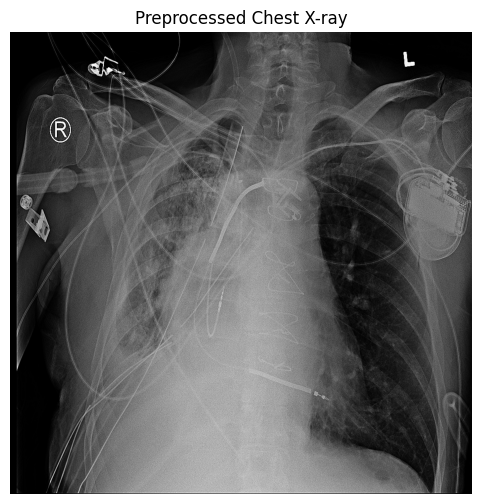

In [ ]:
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

# Get preprocessed images
processed_files = sorted(output_dir.glob("*.png"))

print("Total preprocessed images:", len(processed_files))

# Select one image
sample_path = processed_files[0]

# Read image
processed_image = cv2.imread(
    str(sample_path),
    cv2.IMREAD_GRAYSCALE
)

# Display the processed image
plt.figure(figsize=(6, 6))
plt.imshow(processed_image, cmap="gray")
plt.title("Preprocessed Chest X-ray")
plt.axis("off")
plt.show()

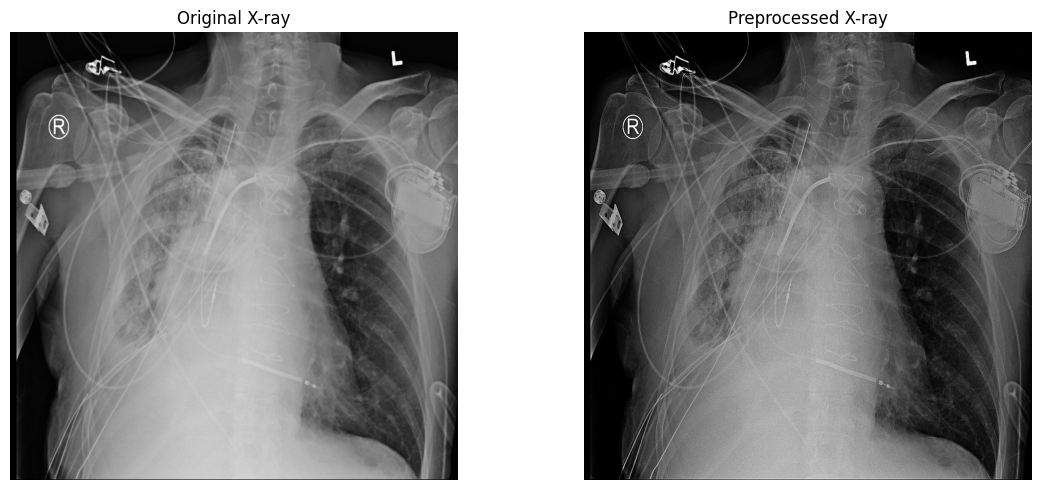

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Read original image
original_path = input_dir / sample_path.name

original_image = cv2.imread(
    str(original_path),
    cv2.IMREAD_GRAYSCALE
)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image, cmap="gray")
plt.title("Preprocessed X-ray")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image

# Image transformations
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])


class ChestXrayDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load image
        image = Image.open(
            row["image_path"]
        ).convert("L")

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        # Label
        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, label

In [ ]:
import pandas as pd
from pathlib import Path

# Project directory
project_dir = Path(
    "/content/drive/MyDrive/NIH_ChestXray14_Project"
)

# Load metadata
subset_csv = project_dir / "subset_selection.csv"
subset_df = pd.read_csv(subset_csv)

# Preprocessed image directory
output_dir = (
    project_dir / "images" / "preprocessed_images"
)

# Create image paths
subset_df["image_path"] = subset_df["Image Index"].apply(
    lambda name: str(output_dir / name)
)

# Verify images
subset_df["exists"] = subset_df["image_path"].apply(
    lambda path: Path(path).exists()
)

print("Total records:", len(subset_df))
print("Images found:", subset_df["exists"].sum())
print("Images missing:", (~subset_df["exists"]).sum())

Total records: 2862
Images found: 2862
Images missing: 0


In [ ]:
from sklearn.model_selection import train_test_split

# Select train_val records
train_val_df = subset_df[
    subset_df["split"] == "train_val"
].copy()

# Split into training and validation sets
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.2,
    stratify=train_val_df["label"],
    random_state=42
)

# Select test records
test_df = subset_df[
    subset_df["split"] == "test"
].copy()

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display results
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

print("\nTest class distribution:")
print(test_df["label"].value_counts())

Training images: 1401
Validation images: 351
Test images: 1110

Training class distribution:
label
1    701
0    700
Name: count, dtype: int64

Validation class distribution:
label
0    176
1    175
Name: count, dtype: int64

Test class distribution:
label
1    555
0    555
Name: count, dtype: int64


In [ ]:
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image

# Image transformations
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])


class ChestXrayDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load preprocessed image
        image = Image.open(
            row["image_path"]
        ).convert("L")

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        # Get label
        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, label

In [ ]:
# Create training dataset
train_dataset = ChestXrayDataset(
    train_df,
    transform=image_transform
)

# Create validation dataset
val_dataset = ChestXrayDataset(
    val_df,
    transform=image_transform
)

# Create test dataset
test_dataset = ChestXrayDataset(
    test_df,
    transform=image_transform
)

# Check dataset sizes
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

# Check one sample
sample_image, sample_label = train_dataset[0]

print("\nSample image shape:", sample_image.shape)
print("Sample label:", sample_label.item())

Training dataset: 1401
Validation dataset: 351
Test dataset: 1110

Sample image shape: torch.Size([1, 224, 224])
Sample label: 0


In [ ]:
from torch.utils.data import DataLoader

# Batch size
batch_size = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

# Check DataLoader sizes
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Check one batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Training batches: 44
Validation batches: 11
Test batches: 35

Batch image shape: torch.Size([32, 1, 224, 224])
Batch label shape: torch.Size([32])


In [ ]:
from torchvision import transforms

# Update image transformation for ResNet18
image_transform_rgb = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("RGB transformation created successfully!")

RGB transformation created successfully!


In [ ]:
# Recreate datasets using RGB transformation

train_dataset = ChestXrayDataset(
    train_df,
    transform=image_transform_rgb
)

val_dataset = ChestXrayDataset(
    val_df,
    transform=image_transform_rgb
)

test_dataset = ChestXrayDataset(
    test_df,
    transform=image_transform_rgb
)

# Check one sample
sample_image, sample_label = train_dataset[0]

print("Sample image shape:", sample_image.shape)
print("Sample label:", sample_label.item())

Sample image shape: torch.Size([3, 224, 224])
Sample label: 0


In [ ]:
from torch.utils.data import DataLoader

# Batch size
batch_size = 32

# Create updated DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

# Check one batch
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])


In [ ]:
# Get one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

print("Unique labels:", labels.unique().tolist())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.640000104904175
Unique labels: [0, 1]


In [ ]:
import torch

# Check GPU availability
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Selected device: cuda
GPU name: Tesla T4


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet18
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the final classification layer
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    2
)

# Move model to GPU
model = model.to(device)

print("ResNet18 model loaded successfully!")
print("Output classes: 2")
print("Model device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 74.9MB/s]


ResNet18 model loaded successfully!
Output classes: 2
Model device: cuda


In [ ]:
import torch.nn as nn
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", 0.0001)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.0001


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss and accuracy
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Track loss and accuracy
            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
num_epochs = 3

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

Epoch [1/3] | Train Loss: 0.6193 | Train Accuracy: 0.6688 | Val Loss: 0.5883 | Val Accuracy: 0.7379
Epoch [2/3] | Train Loss: 0.2783 | Train Accuracy: 0.8887 | Val Loss: 0.7119 | Val Accuracy: 0.6866
Epoch [3/3] | Train Loss: 0.0758 | Train Accuracy: 0.9843 | Val Loss: 0.8934 | Val Accuracy: 0.6952


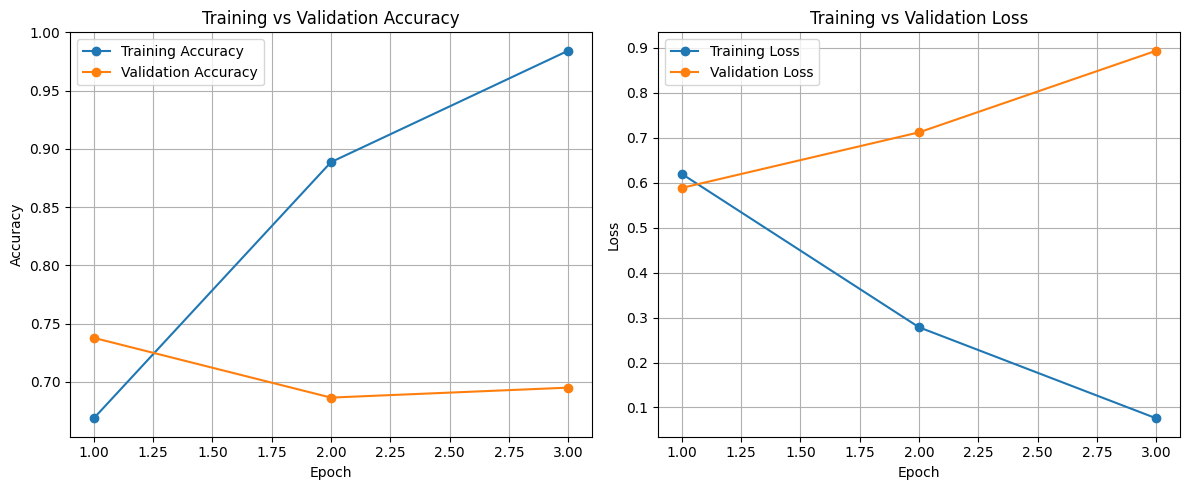

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)

plt.plot(
    epochs,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions)
sensitivity = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)

cm = confusion_matrix(all_labels, all_predictions)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print("Test Evaluation Results")
print("-----------------------")
print(f"Accuracy:     {accuracy:.4f}")
print(f"Precision:    {precision:.4f}")
print(f"Sensitivity:  {sensitivity:.4f}")
print(f"Specificity:  {specificity:.4f}")
print(f"F1-Score:     {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Normal", "Pneumonia"]
))

Test Evaluation Results
-----------------------
Accuracy:     0.6586
Precision:    0.6117
Sensitivity:  0.8685
Specificity:  0.4486
F1-Score:     0.7178

Confusion Matrix:
[[249 306]
 [ 73 482]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.77      0.45      0.57       555
   Pneumonia       0.61      0.87      0.72       555

    accuracy                           0.66      1110
   macro avg       0.69      0.66      0.64      1110
weighted avg       0.69      0.66      0.64      1110



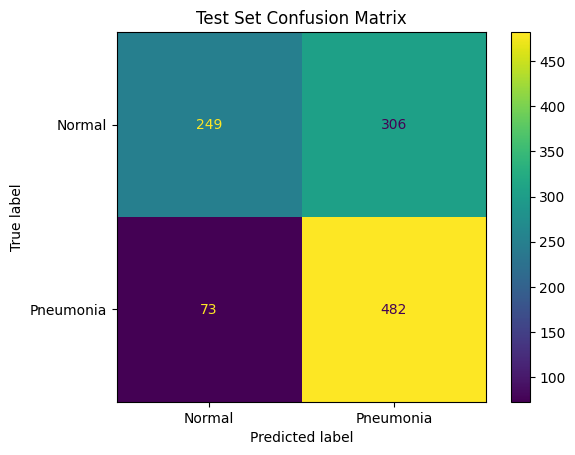

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot(values_format="d")

plt.title("Test Set Confusion Matrix")
plt.show()

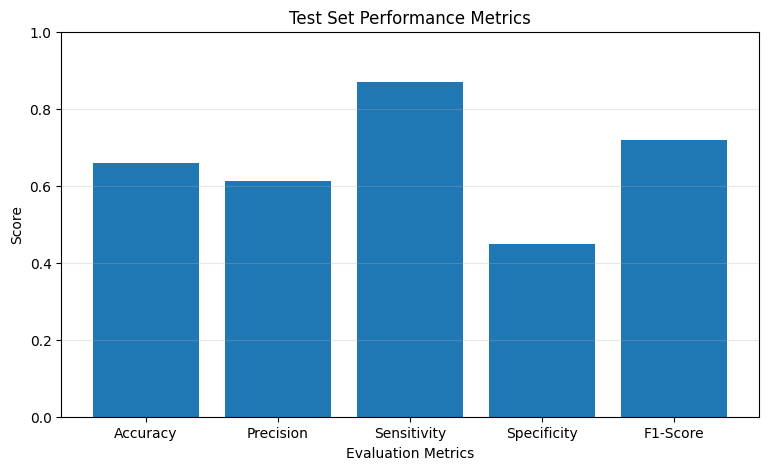

In [ ]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1-Score"
]

values = [
    accuracy,
    precision,
    sensitivity,
    specificity,
    f1
]

plt.figure(figsize=(9, 5))

plt.bar(metrics, values)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Test Set Performance Metrics")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

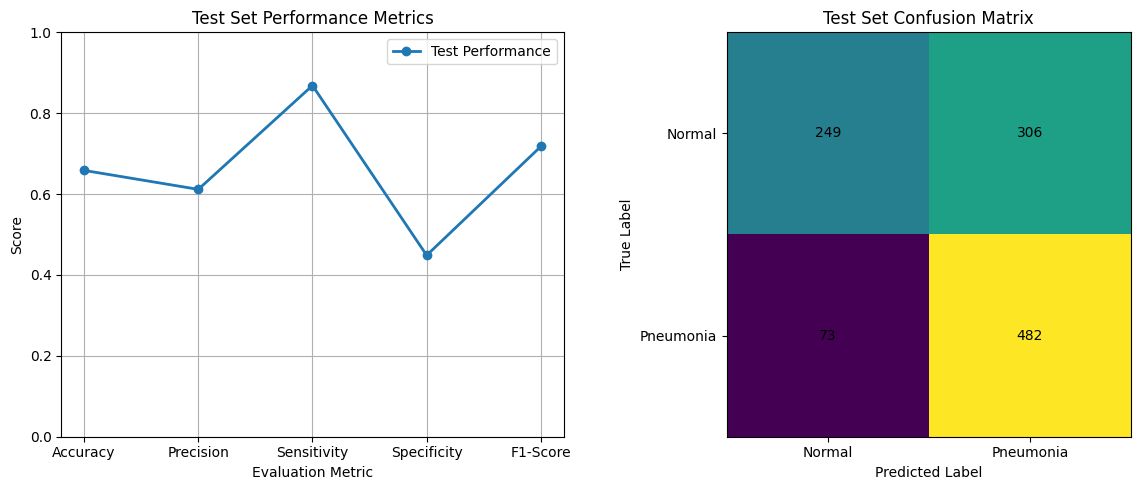

In [ ]:
import matplotlib.pyplot as plt

# Test metrics
metrics = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1-Score"
]

values = [
    accuracy,
    precision,
    sensitivity,
    specificity,
    f1
]

plt.figure(figsize=(12, 5))

# Test Performance Metrics
plt.subplot(1, 2, 1)

plt.plot(
    metrics,
    values,
    marker="o",
    linewidth=2,
    label="Test Performance"
)

plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.title("Test Set Performance Metrics")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)

# Confusion Matrix
plt.subplot(1, 2, 2)

plt.imshow(cm, interpolation="nearest")

plt.title("Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    [0, 1],
    ["Normal", "Pneumonia"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Pneumonia"]
)

# Add values inside confusion matrix
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1-Score"
    ],
    "Value": [
        accuracy,
        precision,
        sensitivity,
        specificity,
        f1
    ]
})

results_path = project_dir / "test_evaluation_results.csv"

test_results.to_csv(results_path, index=False)

print("Test results saved successfully at:")
print(results_path)

Test results saved successfully at:
/content/drive/MyDrive/NIH_ChestXray14_Project/test_evaluation_results.csv


In [ ]:
model_path = project_dir / "resnet18_pneumonia_model.pth"

torch.save(model.state_dict(), model_path)

print("Model saved successfully at:")
print(model_path)

Model saved successfully at:
/content/drive/MyDrive/NIH_ChestXray14_Project/resnet18_pneumonia_model.pth
